# The Hydrogen Atom

The electron of a hydrogen atom moves in the Coulomb potential $-1/r$ of the nucleus. We use atomic units
($\hbar = m = e = 1$): lengths are measured in Bohr radii and energies in Hartree. For a state with angular
momentum $l$, the wave function is $\psi = \frac{u(r)}{r}\, Y_{lm}(\theta, \varphi)$, and the radial function
$u$ satisfies

$$
-\frac{1}{2}\, u'' + \left[ \frac{l(l+1)}{2 r^2} - \frac{1}{r} \right] u = E\, u, \qquad u(0) = 0,
$$

on the half line $0 \le r < \infty$. The bound states have the energies

$$
E_n = -\frac{1}{2 n^2}, \qquad n = l + 1,\ l + 2,\ \ldots
$$

The domain is unbounded, and the states grow quickly with $n$: the mean radius of the state $n$ is of the
order $n^2$. The traditional approach puts the atom into a box, $0 \le r \le r_{\max}$ with
$u(r_{\max}) = 0$, and has to check that the box does not disturb the states of interest. *numgrids* can
discretize the half line itself: the axis `semi_infinite` has no outer end, so there is no box, no cut-off
radius and no boundary condition at infinity.

In this notebook we

1. compute the energy levels for $l = 0, 1, 2$ and compare with the exact values,
2. compare the wave functions and the mean radii $\langle r \rangle$ with the exact ones,
3. study the role of the **scale length** of the axis,
4. compare with the traditional truncated domain,
5. take a brief look at the whole real line with the axis `infinite`.

## The Half Line

`semi_infinite(n, scale)` creates an axis on $[0, \infty)$. Its points are Chebyshev points that are mapped
to the half line by $r = L\,(1 + \xi)/(1 - \xi)$ with the scale length $L$ = `scale`. The first point is
$r = 0$, half of the points lie in $[0, L]$, and the others thin out towards infinity without reaching it.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numgrids import *

grid = Grid(r=semi_infinite(64, scale=20.0))
r = grid.coords

print(grid)
print("boundary faces:      ", list(grid.faces))
print("first points:        ", np.round(r[:4], 4))
print("points in [0, 20]:   ", np.sum(r <= 20))
print("points in [0, 200]:  ", np.sum(r <= 200))
print("outermost point:      r =", round(r[-1]))

Grid(shape=(64,), ndims=1, axes=[
    SemiInfiniteAxis(num_points=64, low=0.0, high=inf, scale=20.0, name='r')
])
boundary faces:       ['0_low']
first points:         [0.     0.0122 0.049  0.1106]
points in [0, 20]:    32
points in [0, 200]:   52
outermost point:      r = 130723


The grid has a single boundary face, the lower end $r = 0$ of the axis (face `"0_low"`, which can also be
addressed by the axis name as `"r_low"`). The upper end is not a boundary. Of the 64 points, 52 lie within
$r \le 200$, and the remaining twelve reach out to $r \approx 130\,000$, far beyond any state we are
going to compute.

## The Radial Hamiltonian

The Hamiltonian is the formula above: a second derivative plus the effective potential as an array on the
grid. The potential is singular at the first grid point $r = 0$. This is the point where the Dirichlet
condition $u(0) = 0$ holds, so the value of the potential there does not enter the problem. It only has to
be finite, and we set it to zero.

In [2]:
def hamiltonian(grid, l=0):
    r = grid.coords
    V = np.zeros(grid.shape)
    V[1:] = l * (l + 1) / (2 * r[1:]**2) - 1 / r[1:]      # r[0] = 0 is the Dirichlet point
    return -0.5 * grid.diff_operator(2) + V


E, _ = hamiltonian(grid).eig(k=6, bcs=0, which="SR")

print(" n     numerical           exact               error")
for n, En in enumerate(E, start=1):
    print(f"{n:2d}   {En:18.14f}  {-1 / (2 * n**2):18.14f}   {abs(En + 1 / (2 * n**2)):8.1e}")

 n     numerical           exact               error
 1    -0.50000000000000   -0.50000000000000    7.2e-16
 2    -0.12500000000000   -0.12500000000000    8.6e-16
 3    -0.05555555555556   -0.05555555555556    3.1e-16
 4    -0.03125000000000   -0.03125000000000    6.6e-17
 5    -0.02000000000001   -0.02000000000000    1.3e-14
 6    -0.01388888888883   -0.01388888888889    5.8e-14


`eig` gets the condition $u(0) = 0$ as `bcs=0` and returns the eigenvalues with the smallest real part
(`which="SR"`). Nothing is said about infinity. Solutions that grow like $e^{+\sqrt{-2E}\,r}$ cannot be
represented on this axis, so only the decaying ones remain. With 64 grid points, the first six levels of
the s states ($l = 0$) are correct to 13 digits or better.

## Energy Levels and Their Degeneracy

The centrifugal term $l(l+1)/(2r^2)$ changes the potential, but for the Coulomb potential the energies
depend on $n$ only. The levels for $l = 0, 1, 2$ therefore coincide wherever they exist ($n > l$).

In [3]:
n_max = 6
levels = {l: hamiltonian(grid, l).eig(k=n_max - l, bcs=0, which="SR")[0] for l in range(3)}

print(" n     l = 0               l = 1               l = 2               exact")
for n in range(1, n_max + 1):
    row = "".join(f"{levels[l][n - l - 1]:20.14f}" if n > l else " " * 20 for l in range(3))
    print(f"{n:2d}{row}{-1 / (2 * n**2):20.14f}")

error = max(np.max(np.abs(levels[l] + 1 / (2 * np.arange(l + 1, n_max + 1)**2))) for l in range(3))
print(f"\nlargest error of all levels: {error:.1e}")

 n     l = 0               l = 1               l = 2               exact
 1   -0.50000000000000                                           -0.50000000000000
 2   -0.12500000000000   -0.12500000000000                       -0.12500000000000
 3   -0.05555555555556   -0.05555555555556   -0.05555555555556   -0.05555555555556
 4   -0.03125000000000   -0.03125000000000   -0.03125000000000   -0.03125000000000
 5   -0.02000000000001   -0.02000000000000   -0.02000000000000   -0.02000000000000
 6   -0.01388888888883   -0.01388888888889   -0.01388888888889   -0.01388888888889

largest error of all levels: 5.8e-14


## Wave Functions

The normalized radial functions are known in closed form,

$$
u_{nl}(r) = \sqrt{\left(\frac{2}{n}\right)^{3} \frac{(n - l - 1)!}{2n\,(n + l)!}}\;\,
r\, \rho^{l}\, e^{-\rho/2}\, L_{n-l-1}^{2l+1}(\rho), \qquad \rho = \frac{2r}{n},
$$

with the associated Laguerre polynomials $L_k^{\alpha}$. The simplest ones are
$u_{10} = 2r\,e^{-r}$, $u_{20} = \frac{1}{\sqrt 2}\, r \left(1 - \frac{r}{2}\right) e^{-r/2}$ and
$u_{21} = \frac{1}{2\sqrt 6}\, r^2 e^{-r/2}$.

With `normalize="l2"`, `eig` returns eigenfunctions that are normalized on the grid, $\int_0^\infty u^2\, dr = 1$.
The integral extends over the whole half line. The sign of an eigenfunction is arbitrary, and we choose it
such that $u$ is positive near the origin, like the exact functions. The mean radius

$$
\langle r \rangle = \int_0^\infty r\, u^2\, dr = \frac{3 n^2 - l(l+1)}{2}
$$

is an inner product on the grid, `grid.inner(u, r * u)`.

In [4]:
from math import factorial
from scipy.special import genlaguerre


def u_exact(n, l, r):
    rho = 2 * r / n
    norm = np.sqrt((2 / n)**3 * factorial(n - l - 1) / (2 * n * factorial(n + l)))
    return norm * r * rho**l * np.exp(-rho / 2) * genlaguerre(n - l - 1, 2 * l + 1)(rho)


states = {}
print(" n  l    norm              <r>                exact    max. error of u")
for l in range(3):
    E, u = hamiltonian(grid, l).eig(k=4 - l, bcs=0, which="SR", normalize="l2")
    for n, u_nl in enumerate(u, start=l + 1):
        u_nl = u_nl * np.sign(u_nl[1])                    # positive near the origin
        states[n, l] = u_nl
        print(f"{n:2d} {l:2d}    {grid.norm(u_nl):.12f}   {grid.inner(u_nl, r * u_nl):16.12f}"
              f"   {(3 * n**2 - l * (l + 1)) / 2:6.1f}    {np.max(np.abs(u_nl - u_exact(n, l, r))):.1e}")

 n  l    norm              <r>                exact    max. error of u
 1  0    1.000000000000     1.500000000000      1.5    4.1e-15
 2  0    1.000000000000     6.000000000000      6.0    2.9e-15
 3  0    1.000000000000    13.500000000000     13.5    2.2e-15
 4  0    1.000000000000    23.999999999995     24.0    7.9e-14
 2  1    1.000000000000     5.000000000000      5.0    6.3e-15
 3  1    1.000000000000    12.500000000000     12.5    4.2e-15
 4  1    1.000000000000    22.999999999996     23.0    6.2e-14
 3  2    1.000000000000    10.500000000000     10.5    1.9e-15
 4  2    1.000000000000    20.999999999999     21.0    3.7e-14


Norms, mean radii and the wave functions themselves agree with the exact results to 12 digits or better.

The plot shows the radial probability densities $u_{nl}^2$ of the shells $n = 1, 2, 3$: the probability
of finding the electron at the distance $r$ from the nucleus. The lines are the exact functions, the
markers are the values at the grid points. The points are dense near the nucleus, where the potential
varies rapidly, and get sparser further out, where the wave functions are smooth.

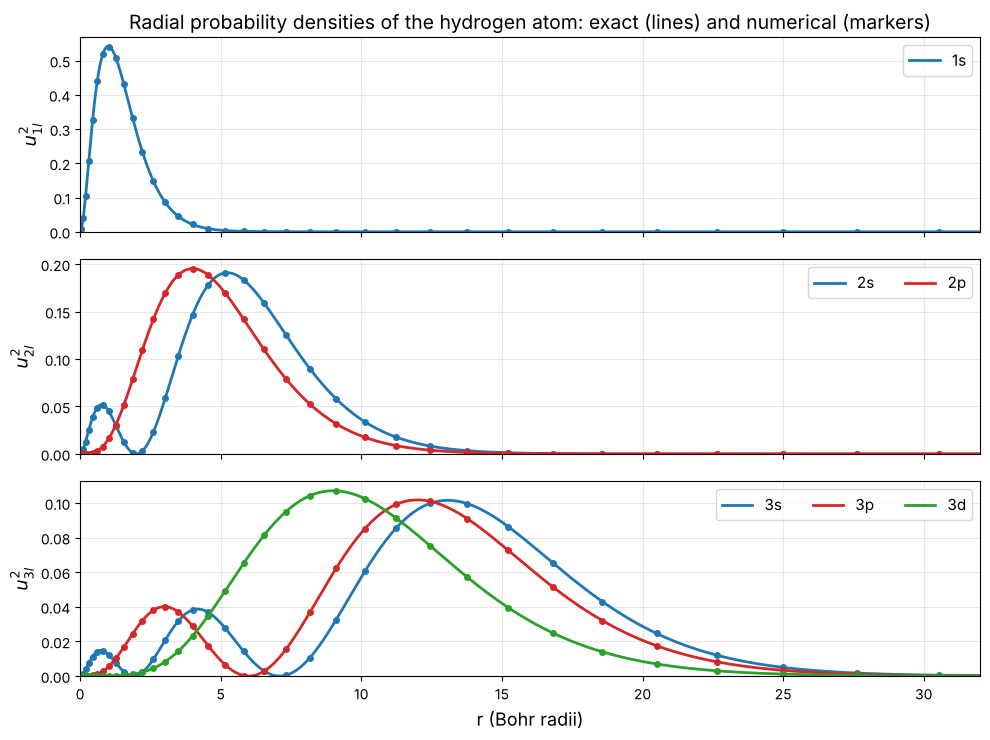

In [5]:
names = "spd"
colors = {0: "tab:blue", 1: "tab:red", 2: "tab:green"}
r_fine = np.linspace(0, 32, 600)

fig, axes = plt.subplots(3, 1, figsize=(10, 7.5), sharex=True)
for n, ax in enumerate(axes, start=1):
    for l in range(n):
        ax.plot(r_fine, u_exact(n, l, r_fine)**2, color=colors[l], linewidth=2, label=f"{n}{names[l]}")
        ax.plot(r, states[n, l]**2, "o", color=colors[l], markersize=4)
    ax.set_xlim(0, 32)
    ax.set_ylim(bottom=0)
    ax.set_ylabel(rf"$u_{{{n}l}}^2$", fontsize=13)
    ax.legend(fontsize=11, loc="upper right", ncol=3)
    ax.grid(True, alpha=0.3)
axes[0].set_title("Radial probability densities of the hydrogen atom: exact (lines) and numerical (markers)",
                  fontsize=14)
axes[-1].set_xlabel("r (Bohr radii)", fontsize=13)
fig.tight_layout()
plt.show()

## The Scale Length

The scale length $L$ decides where the grid points are: half of them in $[0, L]$, the other half beyond.
How should it be chosen? We compute the first three s levels with an increasing number of points for
several values of $L$ and record the largest error.

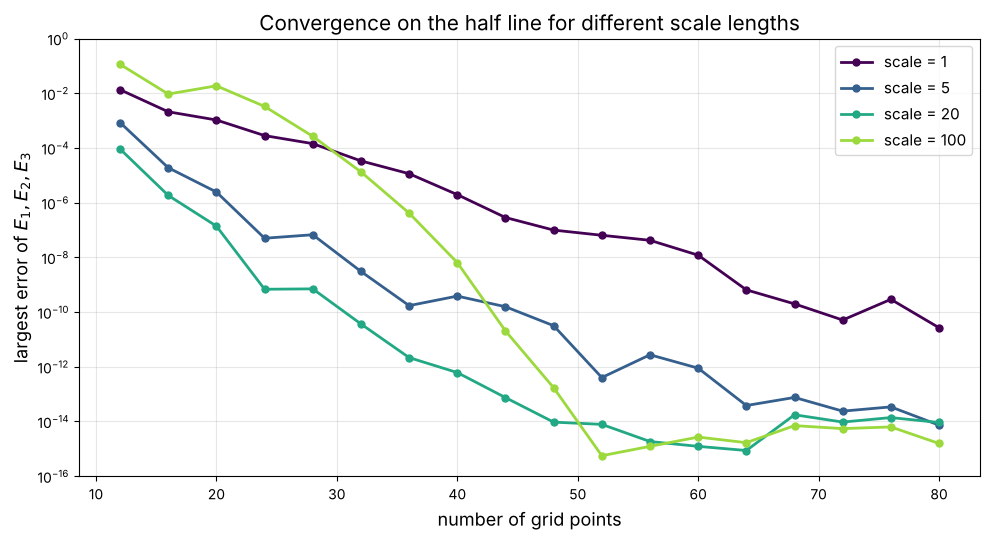

In [6]:
exact = -1 / (2 * np.arange(1, 4)**2)
sizes = np.arange(12, 81, 4)


def level_error(axis):
    E, _ = hamiltonian(Grid(r=axis)).eig(k=3, bcs=0, which="SR")
    return max(np.max(np.abs(E - exact)), 1e-16)           # keep exact hits on the log scale


scale_errors = {L: [level_error(semi_infinite(int(n), scale=L)) for n in sizes]
                for L in (1, 5, 20, 100)}

fig, ax = plt.subplots(figsize=(10, 5.5))
for (L, errors), color in zip(scale_errors.items(), plt.cm.viridis([0.0, 0.3, 0.6, 0.85])):
    ax.semilogy(sizes, errors, "o-", color=color, linewidth=2, markersize=5, label=f"scale = {L}")
ax.set_xlabel("number of grid points", fontsize=13)
ax.set_ylabel(r"largest error of $E_1, E_2, E_3$", fontsize=13)
ax.set_title("Convergence on the half line for different scale lengths", fontsize=15)
ax.set_ylim(1e-16, 1)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)
fig.tight_layout()
plt.show()

All curves fall off faster than any power of the number of points, but at very different rates:

* `scale = 1` is too small. Half of the points are crowded into $r \le 1$, and too few are left for the
  state $n = 3$, which extends to $r \approx 30$.
* `scale = 5` and `scale = 20` place half of the points where the three states live. With `scale = 20`
  the errors reach the level of round-off with about 50 points.
* `scale = 100` is larger than these states require. Coarse grids then have too few points close to the
  nucleus. But the points cluster at $r = 0$, so the error drops quickly once there are about 40 points,
  and it reaches round-off just as early.

The scale length should be of the size of the largest state of interest, and a value that is too large
does less harm than one that is too small. This pays off for highly excited states. The next table shows
the relative errors of the first twelve s levels with 64 points. The state $n = 12$ has the mean radius
$\langle r \rangle = 216$.

In [7]:
principal = np.arange(1, 13)


def relative_errors(axis):
    E, _ = hamiltonian(Grid(r=axis)).eig(k=12, bcs=0, which="SR")
    error = np.abs(2 * principal**2 * E + 1)              # |E_n / E_n(exact) - 1|
    return np.maximum(error, 1e-16)                       # keep exact hits on the log scale


half_line = {L: relative_errors(semi_infinite(64, scale=L)) for L in (20, 100)}

print(" n     scale = 20    scale = 100")
for n in principal:
    print(f"{n:2d}     {half_line[20][n - 1]:8.1e}      {half_line[100][n - 1]:8.1e}")

 n     scale = 20    scale = 100
 1      1.4e-15       3.3e-15
 2      6.9e-15       4.4e-16
 3      5.6e-15       4.0e-15
 4      2.1e-15       1.3e-15
 5      6.5e-13       2.8e-15
 6      4.2e-12       2.9e-15
 7      3.3e-10       2.7e-15
 8      3.7e-09       2.2e-14
 9      3.7e-08       3.2e-13
10      5.5e-07       3.8e-12
11      2.0e-06       6.9e-11
12      1.6e-04       5.3e-10


With `scale = 20` the levels up to $n = 4$ are correct to round-off, and the error grows steadily for
the larger states. With `scale = 100` the same 64 points give all twelve levels to nine digits or better.

## Comparison with a Truncated Domain

The traditional approach is a Chebyshev grid on $[0, r_{\max}]$ with $u(r_{\max}) = 0$. The `hamiltonian`
function works on such a grid as well, and `bcs=0` then applies to both ends. We repeat both experiments
for four box sizes: the convergence of the first three levels, and the first twelve levels with 64 points.

In [8]:
boxes = (50, 100, 200, 400)
box_errors = {R: [level_error(chebyshev(int(n), 0, R)) for n in sizes] for R in boxes}
box_levels = {R: relative_errors(chebyshev(64, 0, R)) for R in boxes}

print("relative errors of the levels with 64 points\n")
print(" n   " + "".join(f"box {R:<8d}" for R in boxes) + "half line (scale = 100)")
for n in principal:
    print(f"{n:2d}   " + "".join(f"{box_levels[R][n - 1]:<12.0e}" for R in boxes)
          + f"{half_line[100][n - 1]:.0e}")

relative errors of the levels with 64 points

 n   box 50      box 100     box 200     box 400     half line (scale = 100)
 1   2e-14       1e-14       2e-09       6e-05       3e-15
 2   7e-15       5e-15       2e-15       5e-08       4e-16
 3   1e-07       4e-16       2e-16       1e-10       4e-15
 4   1e-03       1e-11       1e-15       8e-13       1e-15
 5   1e-01       1e-06       3e-15       1e-14       3e-15
 6   8e-01       1e-03       1e-13       2e-15       3e-15
 7   3e+00       6e-02       6e-09       1e-16       3e-15
 8   7e+00       4e-01       2e-05       3e-15       2e-14
 9   1e+01       1e+00       3e-03       9e-16       3e-13
10   2e+01       3e+00       5e-02       2e-11       4e-12
11   4e+01       5e+00       2e-01       5e-08       7e-11
12   6e+01       9e+00       7e-01       2e-05       5e-10


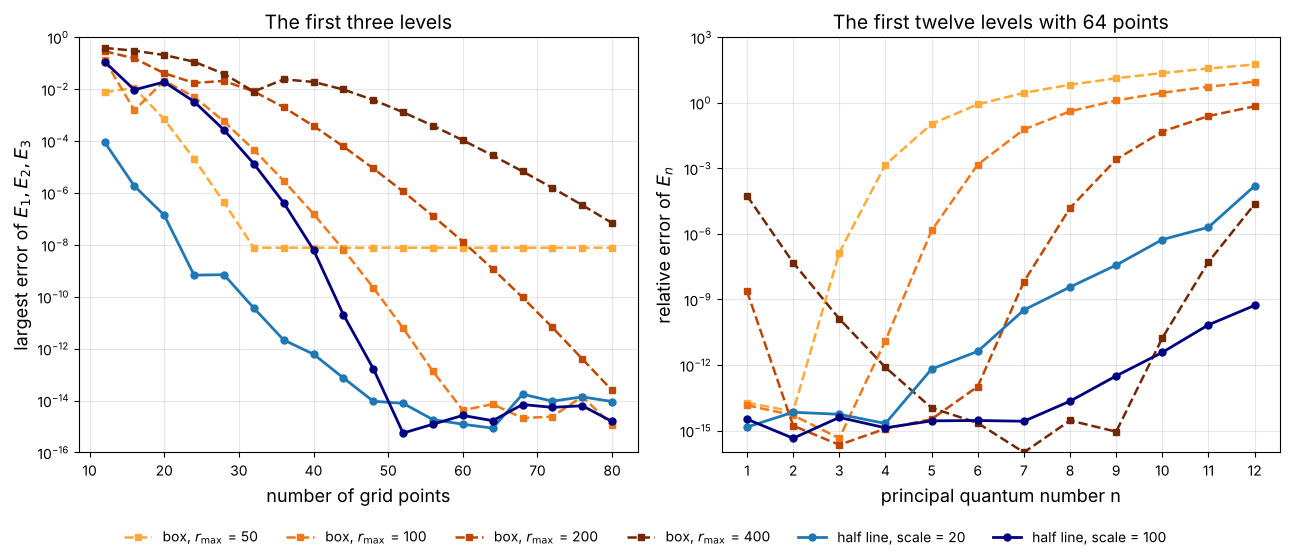

In [9]:
box_colors = dict(zip(boxes, plt.cm.YlOrBr([0.45, 0.6, 0.78, 0.97])))
line_colors = {20: "tab:blue", 100: "navy"}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.6))

for R in boxes:
    ax1.semilogy(sizes, box_errors[R], "s--", color=box_colors[R], linewidth=1.8, markersize=4,
                 label=f"box, $r_{{\\max}}$ = {R}")
    ax2.semilogy(principal, box_levels[R], "s--", color=box_colors[R], linewidth=1.8, markersize=4)
for L in (20, 100):
    ax1.semilogy(sizes, scale_errors[L], "o-", color=line_colors[L], linewidth=2, markersize=5,
                 label=f"half line, scale = {L}")
    ax2.semilogy(principal, half_line[L], "o-", color=line_colors[L], linewidth=2, markersize=5)

ax1.set_xlabel("number of grid points", fontsize=13)
ax1.set_ylabel(r"largest error of $E_1, E_2, E_3$", fontsize=13)
ax1.set_title("The first three levels", fontsize=14)
ax1.set_ylim(1e-16, 1)
ax2.set_xlabel("principal quantum number n", fontsize=13)
ax2.set_ylabel(r"relative error of $E_n$", fontsize=13)
ax2.set_title("The first twelve levels with 64 points", fontsize=14)
ax2.set_xticks(principal)
ax2.set_ylim(1e-16, 1e3)
for ax in (ax1, ax2):
    ax.grid(True, alpha=0.3)

fig.legend(*ax1.get_legend_handles_labels(), loc="lower center", ncol=6, fontsize=10, frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

The left panel shows the dilemma of the box. A small box limits the accuracy: with $r_{\max} = 50$ the
error stays at $10^{-8}$ however many points are used, because the state $n = 3$ does not fit into the
box. A larger box removes this error, but it needs more points for the same resolution near the nucleus:
60 points for $r_{\max} = 100$, 80 points for $r_{\max} = 200$, and $r_{\max} = 400$ is still far from
converged with 80 points. The half line reaches round-off with about 50 points, for both scale lengths.

The right panel shows the same for a fixed number of points. Each box resolves a window of levels. The
large states do not fit into a small box, and a large box is too coarse near the nucleus for the small
states: with $r_{\max} = 400$ the ground state energy has only four correct digits. The half line with
`scale = 100` gives all twelve levels at once: the first eight to 13 digits or better, the others to
nine digits or better.

## A Look at the Whole Line

The axis `infinite(n, scale)` covers the whole real line in the same way. Half of its points lie in
$[-L, L]$, and it has no boundary at all. As an example we take the Pöschl-Teller potential well

$$
V(x) = -\frac{\lambda (\lambda + 1)}{2 \cosh^2 x},
$$

which, unlike the Coulomb potential, has only a finite number of bound states,
$E_n = -\frac{1}{2} (\lambda - n)^2$ for $n = 0, 1, \ldots < \lambda$. No boundary conditions are passed
to `eig`, because there is no boundary.

In [10]:
lam = 4.5
line = Grid(x=infinite(64, scale=4.0))
x = line.coords
H = -0.5 * line.diff_operator(2) - lam * (lam + 1) / (2 * np.cosh(x)**2)

E, psi = H.eig(k=5, which="SR", normalize="l2")

print("boundary faces:", list(line.faces))
print(" n    numerical          exact      error      norm")
for n, En in enumerate(E):
    print(f"{n:2d}   {En:15.11f}   {-(lam - n)**2 / 2:8.3f}   {abs(En + (lam - n)**2 / 2):8.1e}"
          f"   {line.norm(psi[n]):.10f}")

boundary faces: []
 n    numerical          exact      error      norm
 0   -10.12500000000    -10.125    1.0e-12   1.0000000000
 1    -6.12500000001     -6.125    6.5e-12   1.0000000000
 2    -3.12499999998     -3.125    1.8e-11   1.0000000000
 3    -1.12500000002     -1.125    2.4e-11   1.0000000000
 4    -0.12499999999     -0.125    1.2e-11   1.0000000000


The potential well has five bound states, and all of them are found with errors of the order $10^{-11}$.
The scale length is a compromise here: the wave function of the lowest state decays like $e^{-4.5 |x|}$,
that of the highest one like $e^{-0.5 |x|}$.

## Summary

* `semi_infinite(n, scale)` discretizes the half line $[0, \infty)$ with spectral accuracy. The only
  boundary is the finite end; nothing has to be imposed at infinity.
* The radial Schrödinger equation of the hydrogen atom becomes
  `(-0.5 * grid.diff_operator(2) + V).eig(k, bcs=0, which="SR")`. The singular potential only has to be
  given a finite value at the Dirichlet point $r = 0$.
* `normalize="l2"` returns normalized wave functions, and `grid.inner` and `grid.norm` compute expectation
  values over the whole half line.
* The scale length places half of the points within $[0, L]$. A generous value is cheap, a value that is
  too small is not.
* A truncated domain resolves a window of states that fit into the box and are still resolved by its grid.
  The half line covers small and large states with the same grid.
* `infinite(n, scale)` does the same for the whole real line.